Step 1 — Load the data

In [1]:
import pandas as pd
df = pd.read_csv('Groceries_dataset.csv')
df.head()
print(df.shape, df['itemDescription'].nunique())

(38765, 3) 167


Step 2 — Form the baskets

In [2]:
df['basket'] = df['Member_number'].astype(str) + '_' + df['Date'].astype(str)
transactions = df.groupby('basket')['itemDescription'].apply(list).tolist()
transactions[:2] # look at two example baskets

[['sausage', 'whole milk', 'semi-finished bread', 'yogurt'],
 ['whole milk', 'pastry', 'salty snack']]

Step 3 — Encode the baskets

In [3]:
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
basket_table = pd.DataFrame(te.fit_transform(transactions),
    columns=te.columns_)
basket_table.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Step 4 — Find frequent itemsets with Apriori

In [4]:
from mlxtend.frequent_patterns import apriori
frequent_itemsets = apriori(basket_table, min_support=0.001,
use_colnames=True)
frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets
146,0.157923,frozenset({whole milk})
90,0.122101,frozenset({other vegetables})
109,0.110005,frozenset({rolls/buns})
123,0.097106,frozenset({soda})
147,0.085879,frozenset({yogurt})
110,0.069572,frozenset({root vegetables})
139,0.067767,frozenset({tropical fruit})
10,0.060683,frozenset({bottled water})
115,0.060349,frozenset({sausage})
28,0.053131,frozenset({citrus fruit})


Step 5 — Generate the association rules

In [5]:
from mlxtend.frequent_patterns import association_rules
rules = association_rules(frequent_itemsets, metric='lift',
    min_threshold=1)
rules = rules.sort_values('lift', ascending=False)
rules[['antecedents','consequents','support','confidence','lift']].head(10)

,antecedents,consequents,support,confidence,lift
236,"frozenset({yogurt, whole milk})",frozenset({sausage}),0.001470,0.131737,2.182917
237,frozenset({sausage}),"frozenset({yogurt, whole milk})",0.001470,0.024363,2.182917
235,"frozenset({sausage, whole milk})",frozenset({yogurt}),0.001470,0.164179,1.911760
238,frozenset({yogurt}),"frozenset({sausage, whole milk})",0.001470,0.017121,1.911760
86,frozenset({citrus fruit}),frozenset({specialty chocolate}),0.001403,0.026415,1.653762
87,frozenset({specialty chocolate}),frozenset({citrus fruit}),0.001403,0.087866,1.653762
234,"frozenset({sausage, yogurt})",frozenset({whole milk}),0.001470,0.255814,1.619866
239,frozenset({whole milk}),"frozenset({sausage, yogurt})",0.001470,0.009310,1.619866
123,frozenset({tropical fruit}),frozenset({flour}),0.001069,0.015779,1.617141
122,frozenset({flour}),frozenset({tropical fruit}),0.001069,0.109589,1.617141


Step 6 — Visualize and interpret

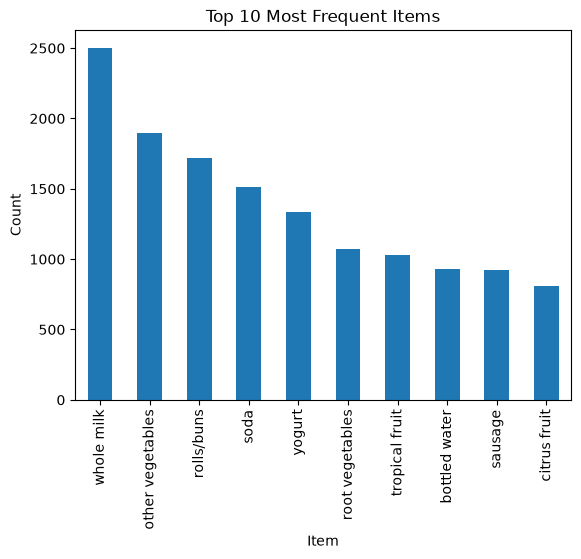

In [6]:
import matplotlib.pyplot as plt
df['itemDescription'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Most Frequent Items')
plt.xlabel('Item'); plt.ylabel('Count'); plt.show()